#  Practical 6 — Neural Networks for Microscopy Data

## Setup

In [1]:
%pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [2]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import optuna
import torch
import torch.nn as nn
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
)
from sklearn.model_selection import (
    GroupShuffleSplit,
    StratifiedGroupKFold,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

RANDOM_STATE = 141026

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


In [3]:
import seaborn as sns

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## Hometask

Same experiment - different representation. Dataset contains same data, but it uses vgg16 embeddings instead of handcrafted morpho characteristics.
>week6\large_object_vgg3d_embeddings_processed.csv

### Task

Build and evaluate a neural-network classifier for `cell_type` using the VGG3D embedding representation. Compare it with at least one simpler model and explain what the results mean biologically and statistically.

Do not use `sample_group` as a predictive feature. Use it only to construct leakage-safe splits.

## Required sections

### 1. Data inspection and preparation checklist

Since data is the same no need to write detailed report but still - check if everything is in order(just in case)


### 2. Exploratory analysis

Show:

- class counts for `m0`, `m1`, and `m2`;
- the distribution of selected embedding features;
- missingness by feature and by row;
- a two-dimensional t-SNE or UMAP visualization coloured by `cell_type`.

Treat t-SNE/UMAP as exploratory visualizations, not as test-set evaluation.

### 3. Leakage-safe splitting and preprocessing

Create training, validation, and test partitions, be sure that you dont introduce any leakege.



### 4. Baseline and MLP model

Train a simple baseline, such as multinomial logistic regression, followed by a PyTorch MLP

Report training and validation loss and accuracy across epochs.

### 5. Experiments

Perform experiments corresponding to the Week 6 explanations:

- compare at least three learning rates;
- compare at least two network capacities;
- identify possible overfitting from learning curves;
- compare weight decay and dropout;
- demonstrate early stopping;
- explain which configuration you select and why.

Keep the random seed fixed when comparing configurations.

### 6. Classical comparison

Compare the selected MLP with:

- logistic regression;
- XGBoost with a small, validation-only hyperparameter search.


### 7. Evaluation

Evaluate the final selected models on the untouched test partition using:

- balanced accuracy;
- macro F1 score;
- a confusion matrix;
- a short class-by-class error analysis.

Do not select the final model using test performance.

## Questions for the report

1. Did the embedding space show visible separation between the cell types?
2. Which learning rate and architecture performed best, and what evidence supports that choice?
3. Did the MLP overfit? Use the training and validation curves to justify your answer.
4. Which regularization method was most useful?
5. How did the MLP compare with logistic regression and XGBoost?
7. Which cell types were most frequently confused?
8. What additional biological or technical information would help explain the errors?

## Deliverables

- completed notebook;
- short report answering the questions above;
- one table comparing the final models;
- figures for the embedding visualization, learning curves, and confusion matrix;
- a brief statement of limitations and possible next steps.

## Load Data

In [4]:
df=pd.read_csv("large_object_vgg3d_embeddings_processed.csv")

In [5]:
df

,cell_type,sample_group,vgg_emb_000,vgg_emb_001,vgg_emb_002,vgg_emb_003,vgg_emb_004,vgg_emb_005,vgg_emb_006,vgg_emb_007,...,vgg_emb_118,vgg_emb_119,vgg_emb_120,vgg_emb_121,vgg_emb_122,vgg_emb_123,vgg_emb_124,vgg_emb_125,vgg_emb_126,vgg_emb_127
0,m0,sample_group_079,0.039772,0.0,1.179048,0.0,0.0,0.0,1.221995,0.0,...,0.0,0.0,0.0,0.797191,1.709197,0.0,0.777199,0.0,1.924863,0.0
1,m0,sample_group_079,0.000000,0.0,4.433527,0.0,0.0,0.0,5.810353,0.0,...,0.0,0.0,0.0,3.935624,6.289729,0.0,2.987612,0.0,8.424339,0.0
2,m0,sample_group_079,0.000000,0.0,4.108049,0.0,0.0,0.0,5.343654,0.0,...,0.0,0.0,0.0,3.621442,5.779456,0.0,2.740911,0.0,7.669261,0.0
3,m0,sample_group_079,0.000000,0.0,4.042331,0.0,0.0,0.0,5.283560,0.0,...,0.0,0.0,0.0,3.587561,5.783239,0.0,2.660382,0.0,7.480461,0.0
4,m0,sample_group_079,0.000000,0.0,2.474535,0.0,0.0,0.0,3.063431,0.0,...,0.0,0.0,0.0,2.021839,3.586300,0.0,1.637182,0.0,4.486126,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,m2,sample_group_056,0.000000,0.0,2.634610,0.0,0.0,0.0,3.325004,0.0,...,0.0,0.0,0.0,2.133105,3.855358,0.0,1.736552,0.0,4.645347,0.0
377,m2,sample_group_012,0.000000,0.0,1.678640,0.0,0.0,0.0,1.937712,0.0,...,0.0,0.0,0.0,1.231254,2.411791,0.0,1.117645,0.0,2.879727,0.0
378,m2,sample_group_012,0.000000,0.0,3.090644,0.0,0.0,0.0,3.945675,0.0,...,0.0,0.0,0.0,2.665728,4.402645,0.0,2.081455,0.0,5.807134,0.0
379,m2,sample_group_012,0.000000,0.0,2.557516,0.0,0.0,0.0,3.187129,0.0,...,0.0,0.0,0.0,2.117242,3.617540,0.0,1.689103,0.0,4.571338,0.0


## EDA

In [6]:
print(df.dtypes.value_counts())

float64    128
object       2
Name: count, dtype: int64


In [7]:
feature_cols = df.select_dtypes(include=np.number).columns.tolist()
print("Numeric features:", len(feature_cols))
print("Non-numeric columns:", df.select_dtypes(exclude=np.number).columns.tolist())

Numeric features: 128
Non-numeric columns: ['cell_type', 'sample_group']


In [8]:
print("Total missing values:", int(df.isna().sum().sum()))
print("Columns with missing values:", df.isna().sum()[lambda s: s > 0])
print("Infinite values:", int(np.isinf(df[feature_cols]).sum().sum()))

missing_by_feature = df[feature_cols].isna().sum()
missing_by_row = df[feature_cols].isna().sum(axis=1)
print("Features with missing values:", int((missing_by_feature > 0).sum()))
print("Rows with missing values:", int((missing_by_row > 0).sum()))


Total missing values: 0
Columns with missing values: Series([], dtype: int64)
Infinite values: 0
Features with missing values: 0
Rows with missing values: 0


In [9]:
print("Duplicated rows:", df.duplicated().sum())
print("Rows with duplicated features:", df[feature_cols].duplicated().sum())

Duplicated rows: 0
Rows with duplicated features: 0


In [10]:
constant_cols = [c for c in feature_cols if df[c].nunique() <= 1]
print("Constant features:", len(constant_cols))
print("Features with negative values:", int((df[feature_cols].min() < 0).sum()))

Constant features: 37
Features with negative values: 0


In [11]:
zero_fraction = (df[feature_cols] == 0).mean()
print("Overall fraction of zeros:", round((df[feature_cols] == 0).values.mean(), 3))
print("Features that are zero in >95% of rows:", int((zero_fraction > 0.95).sum()))

Overall fraction of zeros: 0.577
Features that are zero in >95% of rows: 69


In [12]:
print(df["cell_type"].value_counts().to_frame("objects"))
print(df["cell_type"].value_counts(normalize=True).round(3).to_frame("fraction"))

           objects
cell_type         
m2             145
m0             132
m1             104
           fraction
cell_type          
m2            0.381
m0            0.346
m1            0.273


In [13]:
group_sizes = df["sample_group"].value_counts()
print("Number of sample groups:", group_sizes.shape[0])
print("Group size: min", group_sizes.min(), "| median", group_sizes.median(), "| max", group_sizes.max())


Number of sample groups: 85
Group size: min 1 | median 3.0 | max 22


In [14]:
classes_per_group = df.groupby("sample_group")["cell_type"].nunique()
print("Number of classes per group:")
print(classes_per_group.value_counts().to_frame("groups"))

Number of classes per group:
           groups
cell_type        
1              85


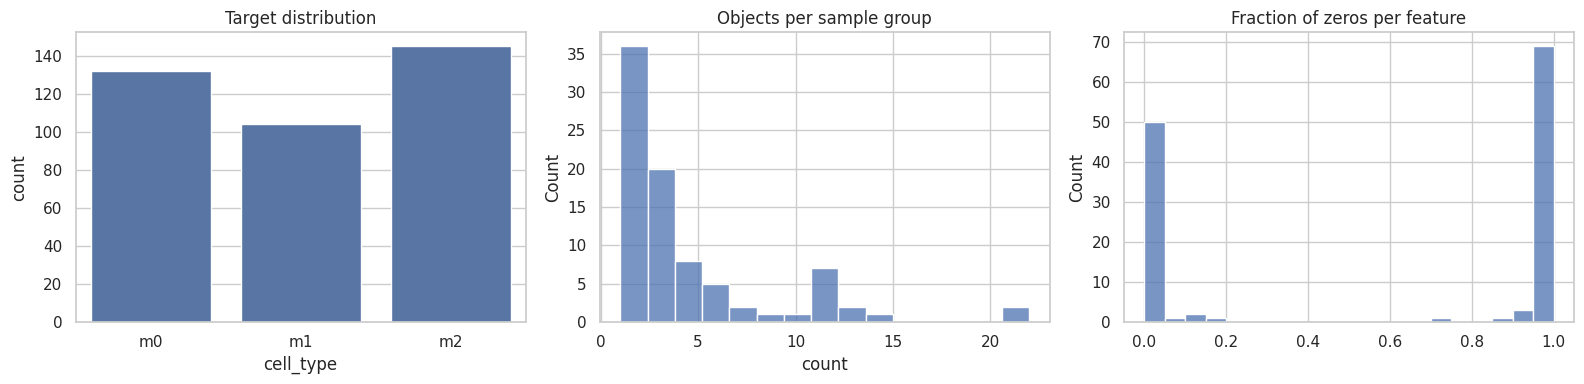

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="cell_type", order=sorted(df["cell_type"].unique()), ax=axes[0])
axes[0].set_title("Target distribution")
sns.histplot(group_sizes, bins=15, ax=axes[1])
axes[1].set_title("Objects per sample group")
sns.histplot(zero_fraction, bins=20, ax=axes[2])
axes[2].set_title("Fraction of zeros per feature")
plt.tight_layout()
plt.show()

In [16]:
df[feature_cols].describe().T.describe().loc[["min", "50%", "max"]]

,count,mean,std,min,25%,50%,75%,max
min,381.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,381.0,0.003450,0.022431,0.000000,0.000000,0.000000,0.000000,0.196355
max,381.0,11.217508,7.495152,0.314221,5.674656,9.600677,15.212442,44.922714


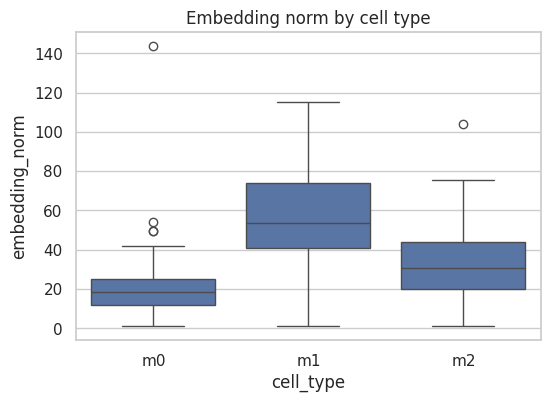

In [17]:
norm_df = pd.DataFrame({
    "cell_type": df["cell_type"],
    "embedding_norm": np.linalg.norm(df[feature_cols].fillna(0), axis=1),
})
plt.figure(figsize=(6, 4))
sns.boxplot(data=norm_df, x="cell_type", y="embedding_norm", order=sorted(df["cell_type"].unique()))
plt.title("Embedding norm by cell type")
plt.show()

In [18]:
pd.crosstab(df["sample_group"], df["cell_type"]).head(15)

cell_type,m0,m1,m2
sample_group,,,
sample_group_000,0,0,12
sample_group_001,0,1,0
sample_group_002,0,2,0
sample_group_003,0,2,0
sample_group_004,0,0,6
sample_group_005,0,4,0
sample_group_006,2,0,0
sample_group_007,0,1,0
sample_group_008,0,2,0


Selected features (highest variance): ['vgg_emb_089', 'vgg_emb_050', 'vgg_emb_126', 'vgg_emb_047']


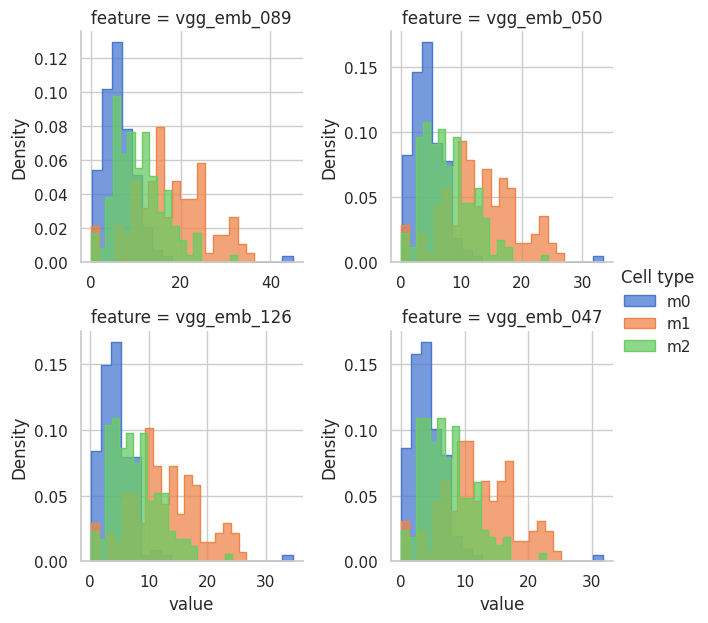

In [19]:
selected = df[feature_cols].var().sort_values(ascending=False).head(4).index.tolist()
print("Selected features (highest variance):", selected)
long_df = df.melt(id_vars="cell_type", value_vars=selected, var_name="feature", value_name="value")

g = sns.FacetGrid(long_df, col="feature", col_wrap=2, hue="cell_type", palette="muted", sharex=False, sharey=False, height=3.2)
g.map_dataframe(sns.histplot, x="value", bins=20, element="step", stat="density", common_norm=False)
g.add_legend(title="Cell type")
plt.show()

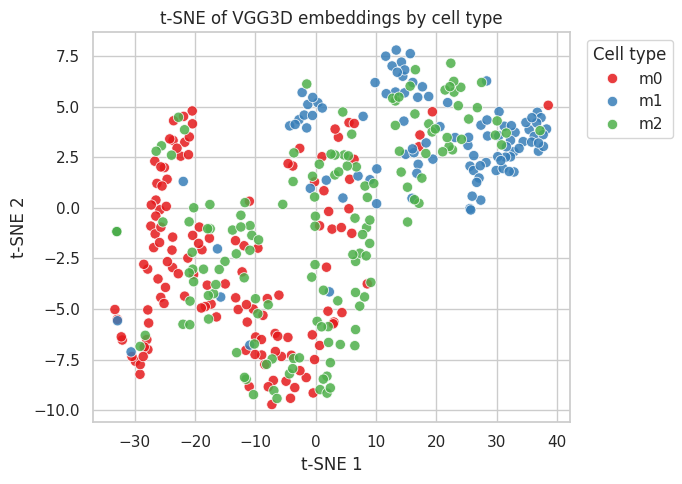

In [20]:
X_vis = df[feature_cols].fillna(df[feature_cols].median())
X_vis = StandardScaler().fit_transform(X_vis)

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
coords = tsne.fit_transform(X_vis)

plt.figure(figsize=(7, 5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["cell_type"],
                hue_order=sorted(df["cell_type"].unique()), palette="Set1", s=55, alpha=0.85)
plt.title("t-SNE of VGG3D embeddings by cell type")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Leakage-safe splitting and preprocessing

Imputation was not used because there are no missing values ​​in the data.

In [21]:

torch.manual_seed(RANDOM_STATE)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)


Device: cuda


In [22]:

X = df[feature_cols]
y = df["cell_type"]
groups = df["sample_group"]

def pick_fold(splits, y_values, target_fraction):
    # Choose the fold whose size and class proportions are closest to the ideal
    overall = y_values.value_counts(normalize=True).sort_index()
    def error(idx):
        part = y_values.iloc[idx].value_counts(normalize=True).reindex(overall.index).fillna(0)
        return abs(len(idx) / len(y_values) - target_fraction) + (part - overall).abs().sum()
    return min(splits, key=lambda s: error(s[1]))


In [23]:

# Outer split
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_full_idx, test_idx = pick_fold(list(outer.split(X, y, groups)), y, 0.20)

X_train_full, y_train_full, g_train_full = X.iloc[train_full_idx], y.iloc[train_full_idx], groups.iloc[train_full_idx]
X_test, y_test, g_test = X.iloc[test_idx], y.iloc[test_idx], groups.iloc[test_idx]

# Inner split
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE + 1)
train_idx, val_idx = pick_fold(list(inner.split(X_train_full, y_train_full, g_train_full)), y_train_full, 0.25)

X_train, y_train, g_train = X_train_full.iloc[train_idx], y_train_full.iloc[train_idx], g_train_full.iloc[train_idx]
X_val, y_val, g_val = X_train_full.iloc[val_idx], y_train_full.iloc[val_idx], g_train_full.iloc[val_idx]

In [24]:

# Leakage checks
assert not set(g_train) & set(g_val)
assert not set(g_train) & set(g_test)
assert not set(g_val) & set(g_test)

summary = pd.DataFrame({
    "objects": [len(y_train), len(y_val), len(y_test)],
    "groups": [g_train.nunique(), g_val.nunique(), g_test.nunique()],
}, index=["train", "validation", "test"])
summary = summary.join(pd.concat({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True),
}, axis=1).T.round(3))
summary

,objects,groups,m2,m0,m1
train,223,52,0.408,0.327,0.265
validation,73,16,0.384,0.342,0.274
test,85,17,0.306,0.400,0.294


In [25]:
from sklearn.feature_selection import VarianceThreshold


# Preprocessing (on train only)
selector = VarianceThreshold(threshold=0.0)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(selector.fit_transform(X_train))
X_val_scaled = scaler.transform(selector.transform(X_val))
X_test_scaled = scaler.transform(selector.transform(X_test))

In [26]:
# Class encoding and tensors
class_names = sorted(y.unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

def to_tensors(X_arr, y_ser):
    return (torch.tensor(X_arr, dtype=torch.float32),
            torch.tensor(y_ser.map(class_to_index).to_numpy(), dtype=torch.long))

X_train_t, y_train_t = to_tensors(X_train_scaled, y_train)
X_val_t, y_val_t = to_tensors(X_val_scaled, y_val)
X_test_t, y_test_t = to_tensors(X_test_scaled, y_test)

BATCH_SIZE = 32
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE)
print("Tensor shapes:", X_train_t.shape, X_val_t.shape, X_test_t.shape)

Tensor shapes: torch.Size([223, 91]) torch.Size([73, 91]) torch.Size([85, 91])


##  Baseline and MLP model

In [27]:
import copy
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score

In [28]:
input_dim = X_train_scaled.shape[1]
n_classes = len(class_names)
criterion = nn.CrossEntropyLoss()


In [29]:
# Baseline: multinomial logistic regression

logreg = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)

for name, X_part, y_part in [("train", X_train_scaled, y_train), ("validation", X_val_scaled, y_val)]:
    pred = logreg.predict(X_part)
    print(f"Logistic regression {name}: balanced accuracy = {balanced_accuracy_score(y_part, pred):.3f}, "
          f"macro F1 = {f1_score(y_part, pred, average='macro'):.3f}")


Logistic regression train: balanced accuracy = 0.698, macro F1 = 0.702
Logistic regression validation: balanced accuracy = 0.672, macro F1 = 0.679


In [30]:
# MLP
class FlexibleMLP(nn.Module):
    def __init__(self, input_dim, n_classes, hidden_dims=(32, 16), dropout=0.0):
        super().__init__()
        layers = []
        current_dim = input_dim
        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            current_dim = hidden_dim
        layers.append(nn.Linear(current_dim, n_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


In [31]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)
        pred = logits.argmax(dim=1)
        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        total_loss += loss.item() * X_batch.size(0)
        pred = logits.argmax(dim=1)
        total_correct += (pred == y_batch).sum().item()
        total_samples += X_batch.size(0)

    return total_loss / total_samples, total_correct / total_samples


def fit_experiment(
    hidden_dims=(32, 16),
    lr=1e-3,
    weight_decay=0.0,
    dropout=0.0,
    epochs=30,
    patience=None,
    verbose=False,
):
    torch.manual_seed(RANDOM_STATE)  # same seed for every configuration

    experiment_model = FlexibleMLP(
        input_dim=input_dim,
        n_classes=n_classes,
        hidden_dims=hidden_dims,
        dropout=dropout,
    ).to(DEVICE)

    experiment_optimizer = torch.optim.Adam(
        experiment_model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    experiment_history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    best_state = None
    best_val_loss = np.inf
    best_epoch = epochs
    epochs_without_improvement = 0

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch(
            experiment_model, train_loader, criterion, experiment_optimizer, DEVICE,
        )
        val_loss, val_acc = evaluate(experiment_model, val_loader, criterion, DEVICE)

        experiment_history["train_loss"].append(train_loss)
        experiment_history["val_loss"].append(val_loss)
        experiment_history["train_acc"].append(train_acc)
        experiment_history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(experiment_model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose:
            print(
                f"Epoch {epoch+1:03d} | "
                f"train loss={train_loss:.4f} | val loss={val_loss:.4f} | "
                f"train acc={train_acc:.3f} | val acc={val_acc:.3f}"
            )

        if patience is not None and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        experiment_model.load_state_dict(best_state)

    if verbose:
        print(f"\nBest epoch: {best_epoch} | best val loss={best_val_loss:.4f} | "
              f"val acc at best epoch={experiment_history['val_acc'][best_epoch-1]:.3f}")

    return experiment_model, experiment_history, best_epoch

In [32]:
# Baseline MLP
baseline_model, baseline_history, baseline_best_epoch = fit_experiment(
    hidden_dims=(32, 16), lr=1e-3, epochs=50, verbose=True,
)
print("Trainable parameters:", count_parameters(baseline_model))

Epoch 001 | train loss=1.0870 | val loss=1.1148 | train acc=0.466 | val acc=0.479
Epoch 002 | train loss=1.0473 | val loss=1.1004 | train acc=0.502 | val acc=0.466
Epoch 003 | train loss=1.0116 | val loss=1.0817 | train acc=0.516 | val acc=0.479
Epoch 004 | train loss=0.9731 | val loss=1.0696 | train acc=0.538 | val acc=0.479
Epoch 005 | train loss=0.9335 | val loss=1.0493 | train acc=0.578 | val acc=0.589
Epoch 006 | train loss=0.8947 | val loss=1.0394 | train acc=0.587 | val acc=0.644
Epoch 007 | train loss=0.8593 | val loss=1.0401 | train acc=0.565 | val acc=0.644
Epoch 008 | train loss=0.8316 | val loss=1.0504 | train acc=0.610 | val acc=0.644
Epoch 009 | train loss=0.8115 | val loss=1.0735 | train acc=0.619 | val acc=0.630
Epoch 010 | train loss=0.8011 | val loss=1.1068 | train acc=0.623 | val acc=0.616
Epoch 011 | train loss=0.7897 | val loss=1.1308 | train acc=0.623 | val acc=0.616
Epoch 012 | train loss=0.7801 | val loss=1.1509 | train acc=0.632 | val acc=0.603
Epoch 013 | trai

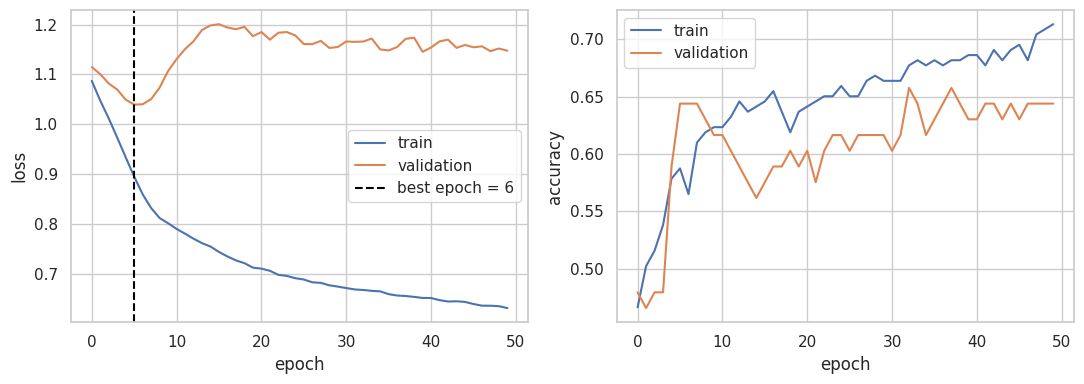

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(baseline_history["train_loss"], label="train")
axes[0].plot(baseline_history["val_loss"], label="validation")
axes[0].axvline(baseline_best_epoch - 1, color="black", linestyle="--", label=f"best epoch = {baseline_best_epoch}")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[1].plot(baseline_history["train_acc"], label="train")
axes[1].plot(baseline_history["val_acc"], label="validation")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

Here we can clearly see overfitting: after epoch 6, training loss keeps falling while validation loss rises, so the network starts memorizing the training objects instead of learning patterns that generalize to new experiments.

## Experiments

### Learning Rate

In [34]:
def summarize(history, best_epoch):
    i = best_epoch - 1
    return {
        "best_epoch": best_epoch,
        "train_loss": history["train_loss"][i],
        "val_loss": history["val_loss"][i],
        "train_acc": history["train_acc"][i],
        "val_acc": history["val_acc"][i],
    }


In [35]:
learning_rates = [1e-4, 1e-3, 1e-2]
lr_results = {}
for learning_rate in learning_rates:
    _, history_lr, best_epoch_lr = fit_experiment(lr=learning_rate, epochs=50)
    lr_results[learning_rate] = {"history": history_lr, "best_epoch": best_epoch_lr}

lr_table = pd.DataFrame(
    {f"lr={lr}": summarize(r["history"], r["best_epoch"]) for lr, r in lr_results.items()}
).T
lr_table.round(4)



,best_epoch,train_loss,val_loss,train_acc,val_acc
lr=0.0001,50.0,0.8702,1.0101,0.5874,0.6438
lr=0.001,6.0,0.8947,1.0394,0.5874,0.6438
lr=0.01,1.0,1.0097,1.1808,0.4978,0.6027


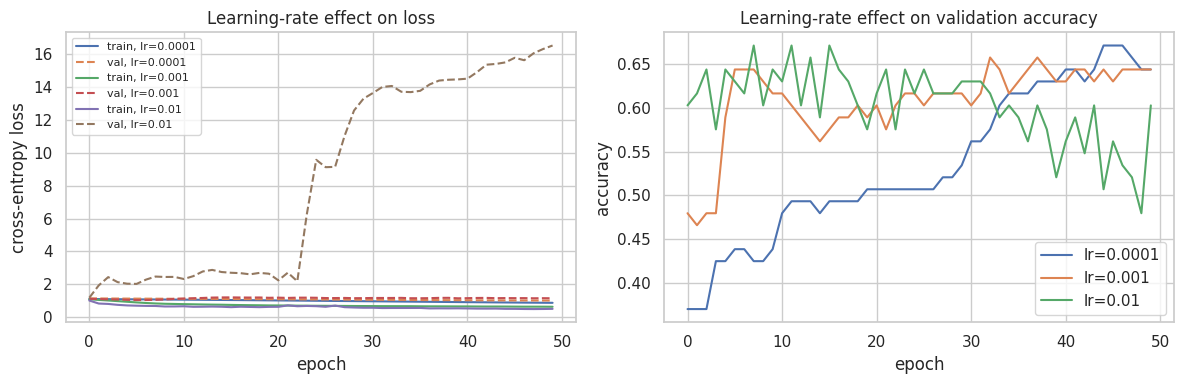

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, result in lr_results.items():
    axes[0].plot(result["history"]["train_loss"], label=f"train, lr={learning_rate:g}")
    axes[0].plot(result["history"]["val_loss"], linestyle="--", label=f"val, lr={learning_rate:g}")
    axes[1].plot(result["history"]["val_acc"], label=f"lr={learning_rate:g}")
axes[0].set_title("Learning-rate effect on loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("cross-entropy loss")
axes[0].legend(fontsize=8)
axes[1].set_title("Learning-rate effect on validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

lr=1e-4 gave the lowest validation loss but had not converged by epoch 50.
lr=1e-3 reached its best at epoch 6 and then overfit.
lr=1e-2 was unstable: validation loss exploded and accuracy oscillated.

I chose lr=1e-4, because it is stable and has the best validation loss, but it needs more epochs

## Network Capacity

In [37]:
BEST_LR = 1e-4

architectures = {
    "small": (8,),
    "medium": (32, 16),
    "wide": (128,),
    "deep": (64, 32, 16),
}

capacity_results = {}
for name, hidden_dims in architectures.items():
    model_cap, history_cap, best_epoch_cap = fit_experiment(
        hidden_dims=hidden_dims, lr=BEST_LR, epochs=50,
    )
    capacity_results[name] = {
        "history": history_cap,
        "best_epoch": best_epoch_cap,
        "parameters": count_parameters(model_cap),
    }

capacity_table = pd.DataFrame(
    {name: {"parameters": r["parameters"], **summarize(r["history"], r["best_epoch"])}
     for name, r in capacity_results.items()}
).T
capacity_table.round(4)

,parameters,best_epoch,train_loss,val_loss,train_acc,val_acc
small,763.0,50.0,0.9062,1.0184,0.5202,0.5205
medium,3523.0,50.0,0.8702,1.0101,0.5874,0.6438
wide,12163.0,12.0,0.9088,1.0456,0.5336,0.5479
deep,8547.0,17.0,1.0237,1.0548,0.5964,0.5753


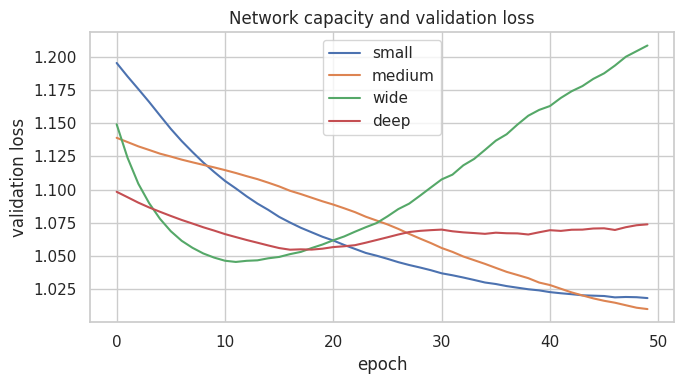

In [38]:

plt.figure(figsize=(7, 4))
for name, result in capacity_results.items():
    plt.plot(result["history"]["val_loss"], label=name)
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.title("Network capacity and validation loss")
plt.legend()
plt.tight_layout()
plt.show()

The medium network (32-16) had the best validation loss and accuracy. The wide net (128) overfit after epoch 12, the deep net plateaued at a higher loss, and the small net was slightly worse in accuracy.

I chose medium (32-16). Here more capacity did not help with 223 training objects.

### Weight decay, dropout, early stopping

In [39]:
BEST_ARCH = (32, 16)

# Weight decay
weight_decay_values = [0.0, 1e-4, 1e-3, 1e-2, 5e-2]
wd_results = {}
for weight_decay in weight_decay_values:
    _, history_wd, best_epoch_wd = fit_experiment(
        hidden_dims=BEST_ARCH, lr=BEST_LR, weight_decay=weight_decay, epochs=50,
    )
    wd_results[weight_decay] = {"history": history_wd, "best_epoch": best_epoch_wd}

# Dropout
dropout_values = [0.0, 0.25, 0.5]
dropout_results = {}
for dropout_rate in dropout_values:
    _, history_do, best_epoch_do = fit_experiment(
        hidden_dims=BEST_ARCH, lr=BEST_LR, dropout=dropout_rate, epochs=50,
    )
    dropout_results[dropout_rate] = {"history": history_do, "best_epoch": best_epoch_do}

# Early stopping (no reg, patience=8)
early_stop_model, early_stop_history, early_stop_best_epoch = fit_experiment(
    hidden_dims=BEST_ARCH, lr=BEST_LR, epochs=100, patience=8, verbose=True,
)




Epoch 001 | train loss=1.1035 | val loss=1.1391 | train acc=0.413 | val acc=0.370
Epoch 002 | train loss=1.0982 | val loss=1.1359 | train acc=0.417 | val acc=0.370
Epoch 003 | train loss=1.0937 | val loss=1.1326 | train acc=0.417 | val acc=0.370
Epoch 004 | train loss=1.0897 | val loss=1.1299 | train acc=0.457 | val acc=0.425
Epoch 005 | train loss=1.0856 | val loss=1.1271 | train acc=0.502 | val acc=0.425
Epoch 006 | train loss=1.0819 | val loss=1.1250 | train acc=0.529 | val acc=0.438
Epoch 007 | train loss=1.0782 | val loss=1.1226 | train acc=0.534 | val acc=0.438
Epoch 008 | train loss=1.0743 | val loss=1.1206 | train acc=0.511 | val acc=0.425
Epoch 009 | train loss=1.0703 | val loss=1.1187 | train acc=0.511 | val acc=0.425
Epoch 010 | train loss=1.0664 | val loss=1.1168 | train acc=0.502 | val acc=0.438
Epoch 011 | train loss=1.0624 | val loss=1.1147 | train acc=0.502 | val acc=0.479
Epoch 012 | train loss=1.0580 | val loss=1.1126 | train acc=0.511 | val acc=0.493
Epoch 013 | trai

In [40]:
# Comparison table
regularization_table = pd.DataFrame({
    **{f"weight decay {wd:g}": summarize(r["history"], r["best_epoch"]) for wd, r in wd_results.items()},
    **{f"dropout {d:g}": summarize(r["history"], r["best_epoch"]) for d, r in dropout_results.items()},
    "early stopping (patience=8)": summarize(early_stop_history, early_stop_best_epoch),
}).T
regularization_table.round(4)

,best_epoch,train_loss,val_loss,train_acc,val_acc
weight decay 0,50.0,0.8702,1.0101,0.5874,0.6438
weight decay 0.0001,50.0,0.8712,1.0102,0.5874,0.6438
weight decay 0.001,50.0,0.8716,1.0081,0.5830,0.6438
weight decay 0.01,50.0,0.8864,0.9953,0.5830,0.6575
weight decay 0.05,50.0,0.9592,1.0202,0.5605,0.5753
dropout 0,50.0,0.8702,1.0101,0.5874,0.6438
dropout 0.25,50.0,0.9495,1.0366,0.5650,0.6301
dropout 0.5,50.0,1.0103,1.0610,0.4664,0.5068
early stopping (patience=8),57.0,0.8442,1.0064,0.6099,0.6301


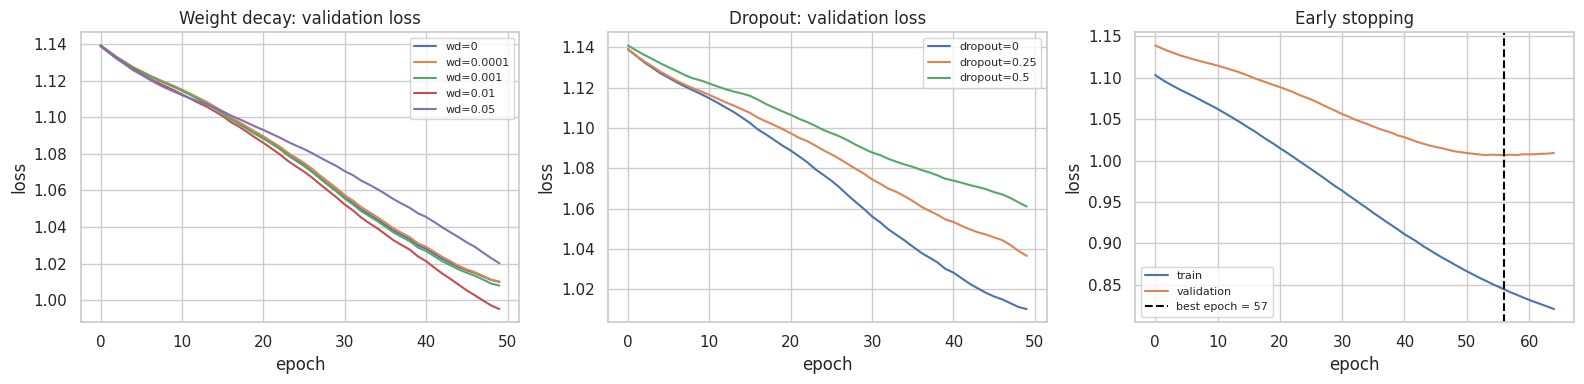

In [41]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for wd, r in wd_results.items():
    axes[0].plot(r["history"]["val_loss"], label=f"wd={wd:g}")
axes[0].set_title("Weight decay: validation loss")
for d, r in dropout_results.items():
    axes[1].plot(r["history"]["val_loss"], label=f"dropout={d:g}")
axes[1].set_title("Dropout: validation loss")
axes[2].plot(early_stop_history["train_loss"], label="train")
axes[2].plot(early_stop_history["val_loss"], label="validation")
axes[2].axvline(early_stop_best_epoch - 1, color="black", linestyle="--", label=f"best epoch = {early_stop_best_epoch}")
axes[2].set_title("Early stopping")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Weight decay 0.01 was the most useful (best val loss). 0.05 was too strong. Dropout did not help (it slowed learning, val loss 1.037 and 1.061 vs 1.010 without). Early stopping (patience 8) stopped at epoch 65 and kept epoch 57 (val loss 1.006).

#### Final

In [42]:
final_model, final_history, final_best_epoch = fit_experiment(
    hidden_dims=(32, 16), lr=1e-4, weight_decay=1e-2,
    epochs=150, patience=8, verbose=True,
)

Epoch 001 | train loss=1.1035 | val loss=1.1390 | train acc=0.413 | val acc=0.370
Epoch 002 | train loss=1.0985 | val loss=1.1356 | train acc=0.417 | val acc=0.370
Epoch 003 | train loss=1.0941 | val loss=1.1322 | train acc=0.417 | val acc=0.370
Epoch 004 | train loss=1.0902 | val loss=1.1292 | train acc=0.453 | val acc=0.425
Epoch 005 | train loss=1.0863 | val loss=1.1262 | train acc=0.498 | val acc=0.425
Epoch 006 | train loss=1.0828 | val loss=1.1237 | train acc=0.529 | val acc=0.438
Epoch 007 | train loss=1.0793 | val loss=1.1211 | train acc=0.534 | val acc=0.452
Epoch 008 | train loss=1.0756 | val loss=1.1189 | train acc=0.516 | val acc=0.438
Epoch 009 | train loss=1.0718 | val loss=1.1168 | train acc=0.511 | val acc=0.425
Epoch 010 | train loss=1.0683 | val loss=1.1147 | train acc=0.507 | val acc=0.438
Epoch 011 | train loss=1.0646 | val loss=1.1125 | train acc=0.498 | val acc=0.479
Epoch 012 | train loss=1.0606 | val loss=1.1102 | train acc=0.511 | val acc=0.479
Epoch 013 | trai

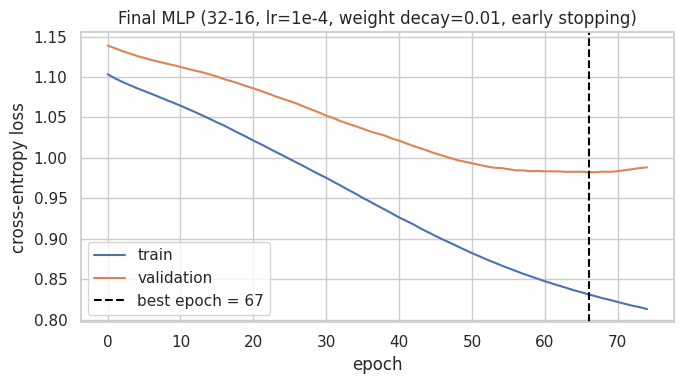

In [43]:
plt.figure(figsize=(7, 4))
plt.plot(final_history["train_loss"], label="train")
plt.plot(final_history["val_loss"], label="validation")
plt.axvline(final_best_epoch - 1, color="black", linestyle="--", label=f"best epoch = {final_best_epoch}")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("Final MLP (32-16, lr=1e-4, weight decay=0.01, early stopping)")
plt.legend()
plt.tight_layout()
plt.show()

Final MLP trained stably and stopped at epoch 75, restoring the epoch 67 checkpoint, which is slightly better than the unregularized model (1.010), so it is a modest improvement rather than a clear one.

## Classical comparison

In [44]:
!pip install optuna -q

In [45]:
import optuna
from xgboost import XGBClassifier

optuna.logging.set_verbosity(optuna.logging.WARNING)

# Encoded labels (same mapping as for the MLP)
y_train_codes = y_train_t.numpy()
y_val_codes = y_val_t.numpy()

In [46]:
def xgb_objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 250, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.7, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0, step=0.1),
        "gamma": trial.suggest_float("gamma", 0.0, 0.5),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }
    model = XGBClassifier(
        objective="multi:softprob",
        num_class=n_classes,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1,
        verbosity=0,
        **params,
    )
    model.fit(X_train_scaled, y_train_codes)
    return f1_score(y_val_codes, model.predict(X_val_scaled), average="macro")



In [47]:
xgb_study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
xgb_study.optimize(xgb_objective, n_trials=20)

print("Best XGBoost parameters:", xgb_study.best_params)
print(f"Best validation macro F1: {xgb_study.best_value:.3f}")


Best XGBoost parameters: {'n_estimators': 50, 'max_depth': 2, 'learning_rate': 0.03632078655399671, 'min_child_weight': 6, 'subsample': 0.7, 'colsample_bytree': 0.8999999999999999, 'gamma': 0.17212352890710422, 'reg_lambda': 0.028322446948774727}
Best validation macro F1: 0.660


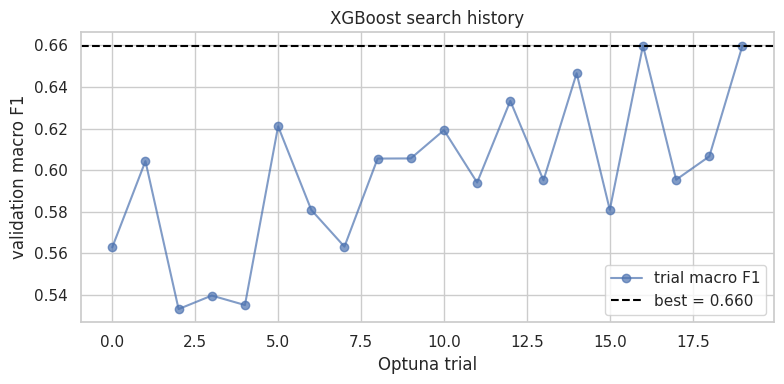

In [48]:
# Optuna search history
plt.figure(figsize=(8, 4))
plt.plot([t.value for t in xgb_study.trials], marker="o", alpha=0.7, label="trial macro F1")
plt.axhline(xgb_study.best_value, color="black", linestyle="--", label=f"best = {xgb_study.best_value:.3f}")
plt.xlabel("Optuna trial")
plt.ylabel("validation macro F1")
plt.title("XGBoost search history")
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
# Final XGBoost
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=n_classes,
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=0,
    **xgb_study.best_params,
)
xgb_model.fit(X_train_scaled, y_train_codes)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8999999999999999, device=None,
              early_stopping_rounds=None, enable_categorical=True,
              eval_metric='mlogloss', feature_types=None, feature_weights=None,
              gamma=0.17212352890710422, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.03632078655399671,
              max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=2, max_leaves=None,
              min_child_weight=6, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=50, n_jobs=1, num_class=3, ...)

In [50]:
@torch.no_grad()
def predict_mlp(model, X_tensor):
    model.eval()
    return model(X_tensor.to(DEVICE)).argmax(dim=1).cpu().numpy()

val_predictions = {
    "Logistic regression": logreg.predict(X_val_scaled),
    "XGBoost": xgb_model.predict(X_val_scaled),
    "MLP": predict_mlp(final_model, X_val_t),
}
train_predictions = {
    "Logistic regression": logreg.predict(X_train_scaled),
    "XGBoost": xgb_model.predict(X_train_scaled),
    "MLP": predict_mlp(final_model, X_train_t),
}

def to_codes(pred):
    return pd.Series(pred).map(class_to_index).to_numpy() if isinstance(pred[0], str) else pred

rows = {}
for name in val_predictions:
    train_pred = to_codes(train_predictions[name])
    val_pred = to_codes(val_predictions[name])
    rows[name] = {
        "train balanced acc": balanced_accuracy_score(y_train_codes, train_pred),
        "val balanced acc": balanced_accuracy_score(y_val_codes, val_pred),
        "val macro F1": f1_score(y_val_codes, val_pred, average="macro"),
    }
pd.DataFrame(rows).T.round(3)

,train balanced acc,val balanced acc,val macro F1
Logistic regression,0.698,0.672,0.679
XGBoost,0.753,0.653,0.660
MLP,0.640,0.657,0.645


On the validation set, all three models perform similarly, and logistic regression is nominally the best, so the neural network gives no clear advantage over simpler models on this small dataset.

The differences are within noise for 73 validation objects, and XGBoost shows the largest train-validation gap, which hints at mild overfitting.

## Final evaluation on the test set

In [51]:
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

y_test_codes = y_test_t.numpy()

test_predictions = {
    "Logistic regression": to_codes(logreg.predict(X_test_scaled)),
    "XGBoost": xgb_model.predict(X_test_scaled),
    "MLP": predict_mlp(final_model, X_test_t),
}



In [52]:
test_rows = {}
for name, pred in test_predictions.items():
    test_rows[name] = {
        "test accuracy": (pred == y_test_codes).mean(),
        "test balanced acc": balanced_accuracy_score(y_test_codes, pred),
        "test macro F1": f1_score(y_test_codes, pred, average="macro"),
    }
final_table = pd.DataFrame(test_rows).T
final_table["val balanced acc"] = pd.DataFrame(rows).T["val balanced acc"]
final_table["val macro F1"] = pd.DataFrame(rows).T["val macro F1"]
final_table.round(3)


,test accuracy,test balanced acc,test macro F1,val balanced acc,val macro F1
Logistic regression,0.576,0.594,0.586,0.672,0.679
XGBoost,0.588,0.597,0.592,0.653,0.660
MLP,0.588,0.588,0.579,0.657,0.645


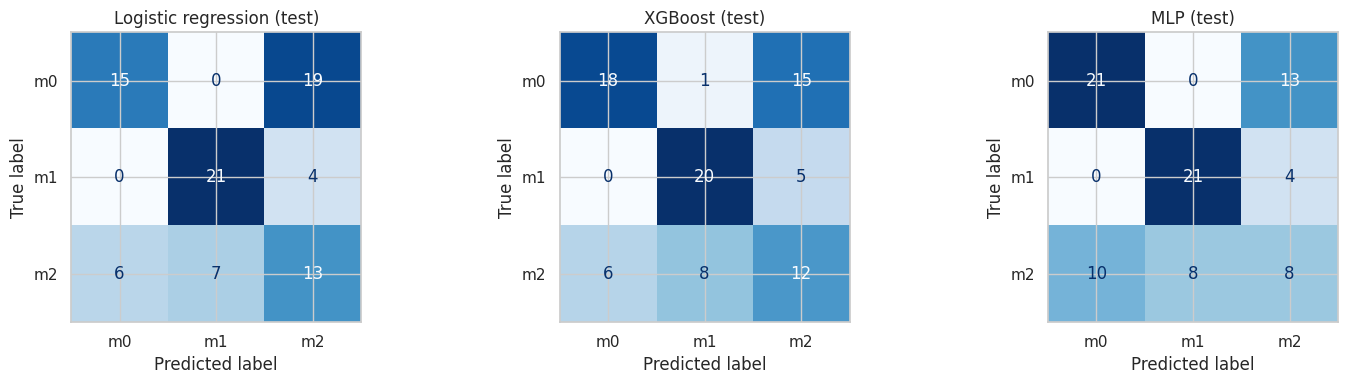

In [53]:

# Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test_codes, pred, display_labels=class_names, cmap="Blues", ax=ax, colorbar=False,
    )
    ax.set_title(f"{name} (test)")
plt.tight_layout()
plt.show()



In [58]:
for name, pred in test_predictions.items():
    print(f"\n    {name} ")
    print(classification_report(y_test_codes, pred, target_names=class_names, digits=3))



    Logistic regression 
              precision    recall  f1-score   support

          m0      0.714     0.441     0.545        34
          m1      0.750     0.840     0.792        25
          m2      0.361     0.500     0.419        26

    accuracy                          0.576        85
   macro avg      0.608     0.594     0.586        85
weighted avg      0.617     0.576     0.580        85


    XGBoost 
              precision    recall  f1-score   support

          m0      0.750     0.529     0.621        34
          m1      0.690     0.800     0.741        25
          m2      0.375     0.462     0.414        26

    accuracy                          0.588        85
   macro avg      0.605     0.597     0.592        85
weighted avg      0.618     0.588     0.593        85


    MLP 
              precision    recall  f1-score   support

          m0      0.677     0.618     0.646        34
          m1      0.724     0.840     0.778        25
          m2      0.320  

In [59]:

cm = confusion_matrix(y_test_codes, test_predictions["MLP"])
cm_share = pd.DataFrame(cm / cm.sum(axis=1, keepdims=True), index=class_names, columns=class_names)
print("\nMLP: row = true class, column = predicted class (share of the true class)")
cm_share.round(2)


MLP: row = true class, column = predicted class (share of the true class)


,m0,m1,m2
m0,0.62,0.00,0.38
m1,0.00,0.84,0.16
m2,0.38,0.31,0.31


On the test set, all three models performed about the same (balanced accuracy 0.59-0.60, macro F1 0.58-0.59), clearly lower than on validation (0.65-0.67).

Neural network gave no advantage over logistic regression or XGBoost. The main error is m2 being confused with m0 and m1, while m1 is recognized best (recall 0.80-0.84) and m0 is never mistaken for m1.

## Questions for the report
1. Did the embedding space show visible separation between the cell types?

Partial. In t-SNE, m0 and m1 occupy different regions, while m2 is spread out and overlaps with both. The embedding-norm boxplot confirms it (m0 low, m1 high, m2 in between). No single feature separates the classes.

2. Which learning rate and architecture performed best, and what evidence supports that choice?

- lr = 1e-4 had the lowest validation loss and was stable. lr = 1e-3 peaked at epoch 6 and then overfit, and lr = 1e-2 was totaly unstable.
- The medium network (32-16) was best. The wide net overfit after epoch 12, the deep net plateaued higher, and the small net had lower accuracy.
- The differences are small on 73 validation objects, so this is slightly better, not clearly better.

3. Did the MLP overfit? Use the training and validation curves to justify your answer.

Yes, at lr = 1e-3: the validation loss was lowest at epoch 6 and then rose while the training loss kept falling. The wide network also overfit. At lr = 1e-4 the overfitting was mild, and both losses fell until about epoch 67.

4. Which regularization method was most useful?

Weight decay 0.01. Dropout slowed learning and did not help. Early stopping avoided the late rise in validation loss. But overral, the gains were modest.

5. How did the MLP compare with logistic regression and XGBoost?

On the test set, all 3 perform almost identically (balanced acc 0.59–0.60). The neural network offered no advantage, and the differences are in range of noise, given the small size of the test set (85 items, 17 groups). So, a simpler model performed the same.

6. Which cell types were most frequently confused?

m2 with m0 and m1. m0 and m1 were almost never confused with each other. m1 was the easiest class (highest F1), and m2 the hardest (lowest F1).

7. What additional biological or technical information would help explain the errors?

- some experiment metadata: bach group has only one class, so batch effects cannot be separated from biology.
- another marker-based labels to check that the m2 labels are consistent.
- more independent experiments per class, and handcrafted morphology features alongside the embeddings.

## Limitations and Next steps



### Limitations
- Small dataset (381 objects, 85 groups). Validation (73) and test (85) sets are small, so results are noisy. Here only jne train/validation/test split was used.
- Class and experiment are perfectly confounded (every group has one class), so models may partly learn technical differences between experiments.
- Test class distribution differ from the overall ones, so balanced accuracy and macro F1 are the main metrics.
- Validation was used for model selection (including 20 Optuna trials), so validation scores are optimistic. This explains the drop from validation to test.
- The final models were trained on train only, not refitted on train + validation.
- 69 of 128 features are almost always zero (ReLU output), and 37 are constant.


### Next steps
- Repeat the evaluation with nested group-aware cross-validation to get confidence intervals.
- Try log1p or other scaling for the sparse embeddings.
- Combine handcrafted morphology features with VGG embeddings.
- Test other or fine-tuned embeddings that may separate m2 better.
- Get experiment metadata, marker-based labels and collect more independent experiments per class.
(If possible)